# Avance 4 — Capítulo 10: Aprendizaje por refuerzo y diseño del entorno del agente
**Práctica de Deep Learning para Finanzas · BTC-USD diario**

**Objetivo:** diseñar el **entorno** del futuro agente (estado, acciones, restricciones, recompensa) y verificar que el simulador es correcto.
**No se entrena ningún agente** (el protocolo no lo exige en este avance).

**Entregables:** (1) especificación del entorno, (2) una transición calculada **a mano**: estado → acción → ejecución → recompensa → nuevo estado,
(3) diferencia entre pronóstico, señal y política aprendida, y descripción de exploración, memoria de experiencias y red objetivo (DQN/DDQN),
(4) seguimiento: ¿podría el agente aprovechar un error del simulador? — con descarte de información futura y contabilidad de costos.

**Insumos de avances anteriores:** la misma partición TR/VA/TE (Avance 1) y los **pronósticos de tu LSTM en VA** con la regla δ = 0.20 % elegida en el Avance 3
(carpeta `insumos_avance3/`). **TE no se usa en este avance.** Corre en CPU (no requiere GPU ni TensorFlow).

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

def _buscar_raiz():
    if os.environ.get("AVANCE4_RAIZ"):
        return Path(os.environ["AVANCE4_RAIZ"])
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        for cand in ("/content/drive/MyDrive/Avance 4 Capitulo 10", "/content/drive/MyDrive/avance4_capitulo10"):
            if (Path(cand) / "dlfin").exists():
                return Path(cand)
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "dlfin").exists() and (p / "insumos_avance3").exists():
            return p
    raise FileNotFoundError("No se encontró la carpeta del avance (debe contener dlfin/, datos/ e insumos_avance3/). Defina AVANCE4_RAIZ.")

RAIZ = _buscar_raiz(); sys.path.insert(0, str(RAIZ))
from dlfin import data, features as F, sim as S
from dlfin.entorno import EntornoTrading, correr_politica, ACCIONES, NOMBRES_ESTADO
from dlfin.errors import Bitacora

SALIDA = RAIZ / "salidas_capitulo10"; (SALIDA / "figuras").mkdir(parents=True, exist_ok=True)
VENTANA, N_RET, CAPITAL, COSTO, SEMILLA = 20, 5, 100_000.0, 0.001, 42
bit = Bitacora()
print("Carpeta del avance:", RAIZ)

Carpeta del avance: C:\Users\alexg\Documents\Escuela\Quinto Semestre\Ciencia de Datos\Proyecto_final\Avance 4 Capitulo 10


## 0. Datos e insumos (solo TR y VA)
Se reconstruyen los precios y la partición del Avance 1 y se cargan los **pronósticos de tu LSTM en VA** (Avance 3). Se comprueba que las fechas coinciden.

In [2]:
crudo = pd.read_csv(RAIZ / "datos" / "originales" / "btc_usd_1d_original.csv")
d, _ = data.limpiar(crudo, bit); data.exigir_minimo(d, 1500)
ind = F.indicadores(d)
ej = F.construir_ejemplos(d, VENTANA, ("ret",), canales_para_inicio=F.CANALES_BASE)
idx = F.particionar(ej); F.verificar_particion(ej, idx)
display(F.tabla_particiones(ej, idx))

ins = RAIZ / "insumos_avance3"
sim3 = pd.read_csv(ins / "simulacion_VA_regla_seleccionada.csv", parse_dates=["fecha", "fecha_emision"])
regla = json.loads((ins / "regla_seleccionada.json").read_text(encoding="utf-8"))
DELTA = float(regla["umbral"])
t_va = ej.idx_emision[idx["VA"]]
assert len(sim3) == len(t_va) == 272
assert (sim3["fecha_emision"].values == d["fecha"].iloc[t_va].values).all(), "las fechas del Avance 3 no coinciden con la partición VA"
assert np.allclose(sim3["precio_ejecucion"].values, d["open"].to_numpy()[t_va + 1], rtol=1e-6), "el precio de ejecución del Avance 3 no es la apertura de t+1"
pron = sim3["pred_rendimiento"].to_numpy()
print(f"Regla heredada del Avance 3: {regla['regla']} (modelo {regla['modelo_senal']}, seleccionada con {regla['seleccionada_con']}, TE usado: {regla['TE_utilizado']})")
print(f"VA: {len(t_va)} pasos, {d.fecha.iloc[t_va[0]].date()} → {d.fecha.iloc[t_va[-1]].date()} (emisión); pronósticos finitos:", bool(np.isfinite(pron).all()))

,conjunto,n_ejemplos,emision_inicial,emision_final,objetivo_inicial,objetivo_final
0,TR,1269,2021-11-15,2025-05-06,2021-11-16,2025-05-07
1,VA,272,2025-05-07,2026-02-02,2025-05-08,2026-02-03
2,TE,272,2026-02-03,2026-11-01,2026-02-04,2026-11-02


Regla heredada del Avance 3: comprar si rendimiento estimado > 0.002; en otro caso efectivo (modelo LSTM, seleccionada con VA, TE usado: False)
VA: 272 pasos, 2025-05-07 → 2026-02-02 (emisión); pronósticos finitos: True


## 1. Especificación del entorno
**Línea de tiempo de un paso** (t = día de emisión):
`cierre de t` → el agente **observa s_t y decide a_t** → `apertura de t+1` → se **ejecuta** a_t (con costo) → `cierre de t+1` → se **valora** el patrimonio y se calcula la **recompensa** → nuevo estado s<sub>t+1</sub>.

### 1.1 Estado s_t (qué conoce el agente al decidir)
| Componente | Definición | Disponible al cierre de t |
|---|---|---|
| `ret_t-4 … ret_t` | 5 últimos rendimientos simples P<sub>i</sub>/P<sub>i-1</sub> − 1 | Sí (solo precios ≤ t) |
| `pronostico_t` | rendimiento estimado para t+1 por el modelo (entrenado en TR, elegido con VA) | Sí (emitido en t) |
| `vol20_t` | desviación estándar muestral de los últimos 20 rendimientos, sin anualizar | Sí |
| `frac_efectivo` | efectivo / patrimonio valorado al cierre de t | Sí (estado de la cuenta) |
| `frac_posicion` | valor de la posición al cierre de t / patrimonio | Sí |

**Lo que el agente NO conoce:** el precio de apertura y de cierre de t+1, el rendimiento y<sub>t</sub> que intenta estimar, cualquier dato de TE y los parámetros futuros de los escaladores.
Dimensión del estado: 9. Se distingue **estar en efectivo** (`frac_posicion = 0`) de **estar comprado** (`frac_posicion > 0`).

### 1.2 Acciones y restricciones
| Acción | Significado | Válida si |
|---|---|---|
| `0 mantener` | **Conserva lo que hay**: si no hay posición = *permanecer en efectivo*; si hay posición = *mantener la posición* (no es lo mismo, y no cobra costo) | siempre |
| `1 comprar` | invierte el 100 % del efectivo (el costo sale del mismo efectivo) | **no** hay posición y hay efectivo |
| `2 vender` | vende **toda** la posición existente | **sí** hay posición |

**Restricciones:** sin apalancamiento (nunca se gasta más que el efectivo disponible), sin posiciones negativas (no hay ventas en corto) y sin recompras de una posición ya abierta
(evita cobrar costos diarios y duplicar exposición). Una acción inválida **se ignora (equivale a mantener) y se registra** en `info["invalida"]`; no se premia ni se castiga en silencio.

### 1.3 Ejecución, costos y recompensa
- **Ejecución:** apertura de t+1 (precio no observable al decidir). Costo académico **0.10 %** sobre el monto negociado en cada compra y en cada venta (compra + venta = 2 cargos).
- **Valoración:** patrimonio V = efectivo + unidades × cierre. Al terminar el episodio se **liquida** la posición al último cierre con costo de venta (misma regla que la simulación del protocolo).
- **Recompensa:** `r_{t+1} = V(cierre de t+1) − V(cierre de t)`, **ya neta de costos** (el costo pagado en la ejecución reduce V). **Se calcula al cierre de t+1**, nunca antes.
  Para el entrenamiento se puede usar la versión relativa `r / V(cierre de t)` (misma señal, escala estable).
- **Episodio:** una secuencia cronológica de pasos (TR para entrenar, VA para elegir; TE queda reservado para una evaluación independiente posterior). Factor de descuento sugerido γ = 0.99.

La clase `EntornoTrading` (`dlfin/entorno.py`) implementa exactamente esta especificación.

In [3]:
env = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET, capital=CAPITAL, costo=COSTO)
espec = {"estado": NOMBRES_ESTADO, "dim_estado": len(NOMBRES_ESTADO), "acciones": {str(k): v for k, v in ACCIONES.items()},
         "restricciones": ["sin apalancamiento", "sin posiciones negativas (sin cortos)", "compra <= efectivo (costo incluido)", "sin recompra con posición abierta"],
         "ejecucion": "apertura de t+1", "recompensa": "V(cierre t+1) - V(cierre t), neta de costos, calculada al cierre de t+1",
         "costo_por_operacion": COSTO, "capital_inicial": CAPITAL, "liquidacion_final": True, "gamma_sugerido": 0.99, "TE_utilizado": False}
(SALIDA / "especificacion_entorno.json").write_text(json.dumps(espec, indent=2, ensure_ascii=False), encoding="utf-8")
est = pd.DataFrame({"componente": NOMBRES_ESTADO, "valor_en_el_primer_paso": env.reset()}); display(est)
est.to_csv(SALIDA / "especificacion_estado.csv", index=False)

,componente,valor_en_el_primer_paso
0,ret_t-4,-0.010507
1,ret_t-3,-0.016433
2,ret_t-2,0.004581
3,ret_t-1,0.021683
4,ret_t,0.002374
5,pronostico_t,0.000738
6,vol20_t,0.018296
7,frac_efectivo,1.000000
8,frac_posicion,0.000000


## 2. Transición calculada a mano: estado → acción → ejecución → recompensa → nuevo estado
Se toma la **primera señal de compra real** de tu LSTM en VA según la regla del Avance 3 (pronóstico > δ = 0.20 %). Primero se calcula **con aritmética explícita** y luego se comprueba contra el entorno.

In [4]:
k = int(np.argmax(pron > DELTA)); t = int(t_va[k])
c = COSTO
# --- estado s_t (todo <= cierre de t)
ret5 = ind["ret"].to_numpy()[t - N_RET + 1: t + 1]; vol_t = ind["vol20"].iloc[t]; close_t = d["close"].iloc[t]
efectivo0, unidades0 = CAPITAL, 0.0
V_t = efectivo0 + unidades0 * close_t
print(f"1) ESTADO s_t   (emisión: cierre del {d.fecha.iloc[t].date()}, P_t = {close_t:,.2f})")
print(f"   rendimientos ult. 5 = {np.round(ret5, 5).tolist()} | pronóstico = {pron[k]:+.6f} | vol20 = {vol_t:.5f}")
print(f"   efectivo = {efectivo0:,.2f} | unidades = {unidades0} | V_t = {V_t:,.2f} | frac_efectivo = 1.0 | frac_posición = 0.0")
# --- acción
print(f"\n2) ACCIÓN a_t   pronóstico {pron[k]:+.4%} > δ = {DELTA:.2%}  y sin posición  →  COMPRAR (válida)")
# --- ejecución
open_t1 = d["open"].iloc[t + 1]
monto = efectivo0 / (1 + c); costo_op = monto * c; unidades1 = monto / open_t1; efectivo1 = round(efectivo0 - monto - costo_op, 9) + 0.0   # = 0 (el costo sale del mismo efectivo; se evita el residuo de punto flotante)
print(f"\n3) EJECUCIÓN    apertura del {d.fecha.iloc[t+1].date()} = {open_t1:,.2f}")
print(f"   monto invertido = {efectivo0:,.2f} / (1 + {c}) = {monto:,.4f}")
print(f"   costo = {monto:,.4f} × {c} = {costo_op:,.4f}  |  unidades = {monto:,.4f} / {open_t1:,.2f} = {unidades1:.8f} BTC  |  efectivo restante = {efectivo1:.6f}")
# --- recompensa
close_t1 = d["close"].iloc[t + 1]
V_t1 = efectivo1 + unidades1 * close_t1
recompensa = V_t1 - V_t
print(f"\n4) RECOMPENSA   (se calcula al cierre del {d.fecha.iloc[t+1].date()}, P_t+1 = {close_t1:,.2f})")
print(f"   V_t+1 = {efectivo1:.4f} + {unidades1:.8f} × {close_t1:,.2f} = {V_t1:,.4f}")
print(f"   r = V_t+1 − V_t = {V_t1:,.4f} − {V_t:,.4f} = {recompensa:+,.4f}   (relativa: {recompensa / V_t:+.4%}, ya incluye el costo de {costo_op:.2f})")
# --- nuevo estado
print(f"\n5) NUEVO ESTADO s_t+1  (cierre del {d.fecha.iloc[t+1].date()}): efectivo = {efectivo1:.4f} | unidades = {unidades1:.8f} | "
      f"frac_efectivo = {efectivo1 / V_t1:.4f} | frac_posición = {unidades1 * close_t1 / V_t1:.4f}  →  ahora el agente está COMPRADO")

# --- verificación contra el entorno (reproduce la secuencia hasta k)
e1 = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET, capital=CAPITAL, costo=COSTO); e1.reset()
for _ in range(k):
    e1.step(0)                                   # permanecer en efectivo hasta la primera señal
p = e1.step(1)
assert abs(p.recompensa - recompensa) < 1e-6 and abs(p.info["costo"] - costo_op) < 1e-9 and abs(e1.cantidad - unidades1) < 1e-12
assert np.isclose(p.estado[7], efectivo1 / V_t1) and np.isclose(p.estado[8], unidades1 * close_t1 / V_t1)
print("\n✔ el entorno reproduce la transición calculada a mano (recompensa, costo, unidades y nuevo estado)")
transicion = pd.DataFrame([{"fecha_emision": d.fecha.iloc[t].date(), "pronostico": pron[k], "accion": "comprar", "fecha_ejecucion": d.fecha.iloc[t+1].date(),
                            "precio_ejecucion(apertura t+1)": open_t1, "monto": monto, "costo": costo_op, "unidades": unidades1, "V_t": V_t, "V_t+1": V_t1,
                            "recompensa": recompensa, "recompensa_relativa": recompensa / V_t}])
display(transicion.T); transicion.to_csv(SALIDA / "transicion_manual.csv", index=False)

1) ESTADO s_t   (emisión: cierre del 2025-11-14, P_t = 94,397.79)
   rendimientos ult. 5 = [0.01219, -0.02829, -0.01295, -0.01934, -0.05316] | pronóstico = +0.002111 | vol20 = 0.02365
   efectivo = 100,000.00 | unidades = 0.0 | V_t = 100,000.00 | frac_efectivo = 1.0 | frac_posición = 0.0

2) ACCIÓN a_t   pronóstico +0.2111% > δ = 0.20%  y sin posición  →  COMPRAR (válida)

3) EJECUCIÓN    apertura del 2025-11-15 = 94,420.47
   monto invertido = 100,000.00 / (1 + 0.001) = 99,900.0999
   costo = 99,900.0999 × 0.001 = 99.9001  |  unidades = 99,900.0999 / 94,420.47 = 1.05803436 BTC  |  efectivo restante = 0.000000

4) RECOMPENSA   (se calcula al cierre del 2025-11-15, P_t+1 = 95,549.15)
   V_t+1 = 0.0000 + 1.05803436 × 95,549.15 = 101,094.2818
   r = V_t+1 − V_t = 101,094.2818 − 100,000.0000 = +1,094.2818   (relativa: +1.0943%, ya incluye el costo de 99.90)

5) NUEVO ESTADO s_t+1  (cierre del 2025-11-15): efectivo = 0.0000 | unidades = 1.05803436 | frac_efectivo = 0.0000 | frac_posición = 

,0
fecha_emision,2025-11-14
pronostico,0.002111
accion,comprar
fecha_ejecucion,2025-11-15
precio_ejecucion(apertura t+1),94420.46875
monto,99900.0999
costo,99.9001
unidades,1.058034
V_t,100000.0
V_t+1,101094.281787


### Las cuatro situaciones del entorno (mantener ≠ comprar ≠ vender; efectivo ≠ posición)
Con datos reales de VA, ejecutadas por el entorno desde el mismo episodio:

In [5]:
e2 = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET, capital=CAPITAL, costo=COSTO); e2.reset()
filas = []
def reg(nombre, paso, e):
    i = paso.info
    filas.append({"situación": nombre, "emisión": i["fecha_emision"].date(), "acción pedida": i["accion_pedida"], "ejecutada": i["accion_ejecutada"], "inválida": i["invalida"],
                  "costo": round(i["costo"], 4), "recompensa": round(paso.recompensa, 4), "efectivo": round(e.efectivo, 2), "unidades": round(e.cantidad, 6)})
reg("A. mantener en efectivo (sin posición)", e2.step(0), e2) if k > 0 else None
for _ in range(max(k - 1, 0)):
    e2.step(0)
reg("B. comprar", e2.step(1), e2)
reg("C. mantener posición (sin costo)", e2.step(0), e2)
reg("D. intento de recompra con posición (inválida, se ignora)", e2.step(1), e2)
reg("E. vender", e2.step(2), e2)
reg("F. intento de venta sin posición (corto: inválida)", e2.step(2), e2)
display(pd.DataFrame(filas)); pd.DataFrame(filas).to_csv(SALIDA / "situaciones_del_entorno.csv", index=False)

,situación,emisión,acción pedida,ejecutada,inválida,costo,recompensa,efectivo,unidades
0,A. mantener en efectivo (sin posición),2025-05-07,mantener,mantener,False,0.0000,0.0000,100000.00,0.000000
1,B. comprar,2025-11-14,comprar,comprar,False,99.9001,1094.2818,0.00,1.058034
2,C. mantener posición (sin costo),2025-11-15,mantener,mantener,False,0.0000,-1451.6975,0.00,1.058034
3,"D. intento de recompra con posición (inválida,...",2025-11-16,comprar,mantener,True,0.0000,-2204.1005,0.00,1.058034
4,E. vender,2025-11-17,vender,vender,False,97.4392,-96.7448,97341.74,0.000000
5,F. intento de venta sin posición (corto: invál...,2025-11-18,vender,mantener,True,0.0000,0.0000,97341.74,0.000000


## 3. Verificaciones del simulador (¿podría el agente recibir una recompensa indebida?)
Antes de avanzar se **descarta información futura** y se **contabilizan los costos**. Cada control es una prueba ejecutable.

**3.1 Invariantes con acciones aleatorias (incluidas inválidas):** nunca efectivo negativo, nunca posición negativa, valores finitos, y
**suma de recompensas = patrimonio final − capital inicial** (si el simulador regalara o perdiera dinero, la suma no cuadraría).

In [6]:
rng = np.random.default_rng(SEMILLA)
mx_err, min_ef, min_cant, n_inv, n_pasos, costos_ok = 0.0, np.inf, np.inf, 0, 0, True
for ep in range(300):
    e = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET, capital=CAPITAL, costo=COSTO); e.reset(); suma = 0.0; c_info = 0.0
    while True:
        p = e.step(int(rng.integers(0, 3)))
        suma += p.recompensa; c_info += p.info["costo"]; n_pasos += 1; n_inv += int(p.info["invalida"])
        min_ef, min_cant = min(min_ef, e.efectivo), min(min_cant, e.cantidad)
        assert np.isfinite(p.recompensa) and e.efectivo >= -1e-9 and e.cantidad >= 0
        if p.terminado:
            break
    mx_err = max(mx_err, abs(suma - (e.patrimonio_final() - CAPITAL)))
    costos_ok &= abs(c_info - e.costos) < 1e-6 and e.costos >= 0
fuzz = pd.DataFrame([{"episodios": 300, "pasos": n_pasos, "acciones_invalidas_ignoradas": n_inv, "efectivo_minimo": min_ef, "unidades_minimas": min_cant,
                      "max|Σrecompensas − (V_final − capital)|": mx_err, "costos_contabilizados_ok": costos_ok}])
display(fuzz.T)
assert min_ef >= -1e-9 and min_cant >= 0 and mx_err < 1e-6 and costos_ok

,0
episodios,300
pasos,81600
acciones_invalidas_ignoradas,27148
efectivo_minimo,0.0
unidades_minimas,0.0
max|Σrecompensas − (V_final − capital)|,0.0
costos_contabilizados_ok,True


**3.2 Sin información futura:** si se **alteran todos los precios posteriores a t**, el estado s<sub>t</sub> no debe cambiar (solo cambia lo que ocurre en t+1: la ejecución y la recompensa).

In [7]:
ok_estado, cambia_ej = [], []
for kk in (0, 5, 40, 120, 250):
    tt = int(t_va[kk]); d2 = d.copy()
    d2.loc[d2.index[tt + 1:], ["open", "high", "low", "close"]] *= 3.0          # futuro alterado
    ind2 = F.indicadores(d2)
    e_a = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET); e_b = EntornoTrading.desde_datos(d2, ind2, t_va, pron, n_ret=N_RET)
    ok_estado.append(bool(np.allclose(e_a.estado(kk), e_b.estado(kk), rtol=1e-12, atol=1e-12)))
    cambia_ej.append(bool(not np.isclose(e_a.open_next[kk], e_b.open_next[kk])))
control_futuro = pd.DataFrame({"paso k": (0, 5, 40, 120, 250), "estado_s_t_igual_con_futuro_alterado": ok_estado, "precio_ejecucion_t+1_si_cambia": cambia_ej})
display(control_futuro); assert all(ok_estado) and all(cambia_ej)

,paso k,estado_s_t_igual_con_futuro_alterado,precio_ejecucion_t+1_si_cambia
0,0,True,True
1,5,True,True
2,40,True,True
3,120,True,True
4,250,True,True


**3.3 Costos bien contabilizados:** un viaje redondo (comprar y vender al mismo precio) debe costar exactamente dos cargos del 0.10 %.

In [8]:
px = np.full(6, 100.0)
e = EntornoTrading(pd.date_range("2025-01-01", periods=6), px, px, px, np.zeros((6, 5)), np.full(6, 0.02), np.zeros(6), capital=CAPITAL, costo=COSTO)
e.reset(); acciones = [1, 2, 0, 0, 0, 0]
for a in acciones:
    p = e.step(a)
esperado = CAPITAL * (1 - COSTO) / (1 + COSTO)
print(f"Viaje redondo a precio constante: V_final = {e.patrimonio_final():,.4f} | esperado CAPITAL×(1−c)/(1+c) = {esperado:,.4f} | pérdida = {1 - e.patrimonio_final() / CAPITAL:.4%} ≈ 2c = {2 * COSTO:.2%}")
assert np.isclose(e.patrimonio_final(), esperado) and np.isclose(e.costos, CAPITAL - esperado)

Viaje redondo a precio constante: V_final = 99,800.1998 | esperado CAPITAL×(1−c)/(1+c) = 99,800.1998 | pérdida = 0.1998% ≈ 2c = 0.20%


## 4. Referencias financieras en VA (mismo entorno, mismos costos)
Efectivo, **comprar y mantener** y la **regla del Avance 3** (LSTM, δ = 0.20 %). El entorno se valida contra el simulador del proyecto (`dlfin.sim`) y contra el archivo del Avance 3.

Entorno vs dlfin.sim: patrimonio final idéntico ✔ | diferencia máxima vs patrimonio diario del Avance 3: 0.000000 USD | señales del Avance 3 = (pronóstico > δ) ✔


,patrimonio_final,rendimiento_neto,max_drawdown,compras,ventas,costos_totales,suma_recompensas
Efectivo,"100,000.00",+0.00%,0.00%,0.000000,0.000000,0.00,0.00
Comprar y mantener,"77,789.47",-22.21%,-39.43%,1.000000,1.000000,177.77,"-22,210.53"
Regla LSTM δ=0.20%,"100,998.53",+1.00%,-2.36%,3.000000,3.000000,605.23,998.53


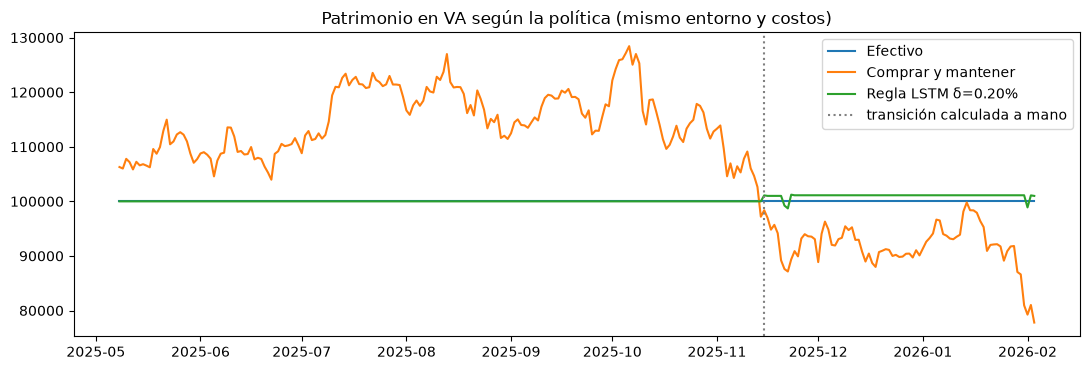

In [9]:
pol_efectivo = lambda s, env: 0
pol_bh = lambda s, env: 1 if not env.en_posicion() and env.k == 0 else 0
def pol_regla(s, env):
    pron_t = s[5]
    if pron_t > DELTA and not env.en_posicion():
        return 1
    if pron_t <= DELTA and env.en_posicion():
        return 2
    return 0
res = {}
for nombre, pol in (("Efectivo", pol_efectivo), ("Comprar y mantener", pol_bh), (f"Regla LSTM δ={DELTA:.2%}", pol_regla)):
    e = EntornoTrading.desde_datos(d, ind, t_va, pron, n_ret=N_RET, capital=CAPITAL, costo=COSTO); res[nombre] = correr_politica(e, pol)
precios = d[["fecha", "open", "high", "low", "close"]]; fe = d["fecha"].iloc[t_va]
senal_regla = res[f"Regla LSTM δ={DELTA:.2%}"]["detalle"]
# señales de la regla = pronóstico > δ (como en el Avance 3); contraste con el simulador del proyecto
sim_regla, r_regla = S.simular(precios, fe, pron > DELTA, CAPITAL, COSTO)
sim_bh, r_bh = S.comprar_y_mantener(precios, fe, CAPITAL, COSTO)
assert np.isclose(res["Comprar y mantener"]["patrimonio_final"], r_bh["patrimonio_final"]) and np.isclose(res[f"Regla LSTM δ={DELTA:.2%}"]["patrimonio_final"], r_regla["patrimonio_final"])
assert (sim3["senal"].to_numpy() == (pron > DELTA).astype(int)).all()
dif_v3 = float(np.abs(res[f"Regla LSTM δ={DELTA:.2%}"]["detalle"]["patrimonio_t1"].to_numpy() - sim3["patrimonio"].to_numpy()).max())
print(f"Entorno vs dlfin.sim: patrimonio final idéntico ✔ | diferencia máxima vs patrimonio diario del Avance 3: {dif_v3:.6f} USD | señales del Avance 3 = (pronóstico > δ) ✔")
tabla = pd.DataFrame({n: {"patrimonio_final": r["patrimonio_final"], "rendimiento_neto": r["rendimiento_neto"], "max_drawdown": r["max_drawdown"],
                          "compras": r["compras"], "ventas": r["ventas"], "costos_totales": r["costos_totales"], "suma_recompensas": r["suma_recompensas"]} for n, r in res.items()}).T
display(tabla.style.format({"patrimonio_final": "{:,.2f}", "rendimiento_neto": "{:+.2%}", "max_drawdown": "{:.2%}", "costos_totales": "{:,.2f}", "suma_recompensas": "{:,.2f}"}))
tabla.to_csv(SALIDA / "referencias_financieras_VA.csv")

fig, ax = plt.subplots(figsize=(11, 3.8))
for n, r in res.items():
    ax.plot(r["detalle"]["fecha_emision"] + pd.Timedelta(days=1), r["detalle"]["patrimonio_t1"], label=n)
ax.axvline(d.fecha.iloc[t + 1], color="gray", ls=":", label="transición calculada a mano"); ax.set_title("Patrimonio en VA según la política (mismo entorno y costos)"); ax.legend(); plt.tight_layout()
plt.savefig(SALIDA / "figuras" / "patrimonio_VA_referencias.png", dpi=130); plt.show()

**Lectura.** El entorno reproduce el simulador del proyecto y el resultado del Avance 3 al centavo (la diferencia máxima diaria se muestra arriba). La rentabilidad de la regla en VA es positiva porque en VA la mayoría de las señales
apenas se activa (6 días en posición) y evita la caída de comprar y mantener; esto **no** garantiza que ocurra lo mismo en TE y no se usa como prueba de capacidad predictiva.

## 5. Pronóstico, señal y política aprendida
| Concepto | Qué es | Ejemplo en este proyecto |
|---|---|---|
| **Pronóstico** | Un **número**: el rendimiento estimado para t+1 | el valor que el modelo emite cada día (columna `pronostico_t`) |
| **Señal** | Una **instrucción derivada de una regla fija** aplicada al pronóstico (todavía no es una operación ejecutada) | «comprar si pronóstico > 0.20 %» |
| **Política aprendida** π(a∣s) | Una **función de estados a acciones** que el agente **aprende** maximizando la recompensa acumulada, usando el estado completo (efectivo, posición, volatilidad…) y los costos | red DQN/DDQN que decide comprar/mantener/vender |

La regla de umbral **no** es una política aprendida: no observa la posición ni los costos al decidir y su parámetro δ se elige a mano con VA. Una política aprendida podría, por ejemplo,
decidir no volver a comprar justo después de vender por no compensar el costo, o mantener una posición aunque el pronóstico baje levemente.

## 6. DQN y DDQN: exploración, memoria de experiencias y red objetivo
**Q(s,a)** estima la recompensa futura descontada de tomar *a* en *s*. DQN la aproxima con una red neuronal (entrada: estado de 9 variables; salida: 3 valores, uno por acción; se enmascaran las acciones inválidas).
- **Exploración (ε-greedy):** con probabilidad ε el agente elige una acción al azar y con 1 − ε la de mayor Q. ε empieza alto (p. ej. 1.0) y **decrece** (p. ej. a 0.05) para explorar al inicio y explotar después. En evaluación (VA/TE) ε = 0.
- **Memoria de experiencias (replay buffer):** se guardan transiciones (s, a, r, s′, terminado) en un buffer de capacidad fija; cada actualización entrena con un **minilote aleatorio**. Rompe la correlación entre pasos consecutivos de una serie de tiempo y reutiliza datos.
  (El buffer solo puede contener transiciones del conjunto de entrenamiento: nunca de VA ni de TE.)
- **Red objetivo (target network):** una **copia retrasada** de la red principal que calcula el *blanco* `y = r + γ · max_a' Q_obj(s', a')`; se actualiza cada C pasos (o con promedio suave τ). Evita perseguir un blanco que cambia en cada actualización y estabiliza el aprendizaje.
- **DDQN:** DQN tiende a **sobreestimar** Q porque el mismo máximo elige y evalúa la acción. DDQN las separa: la **red principal elige** `a* = argmax_a Q(s', a)` y la **red objetivo evalúa** `y = r + γ · Q_obj(s', a*)`.

## 7. Seguimiento: ¿podría el agente aprovechar un error del simulador?
Un agente que maximiza recompensa explota **cualquier** fuga o error contable. Riesgos considerados y cómo se previenen (con la prueba que lo respalda):

In [10]:
riesgos = pd.DataFrame([
    ("Ejecutar al cierre de t o usar precios de t+1 en el estado", "Se ejecuta en la apertura de t+1 y el estado solo contiene datos ≤ t", "3.2: estado idéntico con el futuro alterado"),
    ("No cobrar costo de compra o de venta", "Costo del 0.10 % en cada cambio de posición; el costo sale del efectivo", "3.3: viaje redondo = 2c; costos acumulados = suma de costos por paso"),
    ("Comprar más de lo que hay (apalancamiento) o vender sin tener (corto)", "Máscara de acciones válidas; inválidas se ignoran y se registran", "3.1: efectivo ≥ 0 y unidades ≥ 0 en 300 episodios aleatorios"),
    ("Recompras diarias para manipular costos o exposición", "Comprar con posición abierta es inválido", "Situación D de la sección 2"),
    ("Recompensa duplicada, adelantada o mal alineada", "Se calcula una sola vez al cierre de t+1 como ΔV", "3.1: Σ recompensas = V_final − capital"),
    ("Usar TE (o información de VA) durante el diseño/entrenamiento", "TE no se carga en este avance; el buffer solo recibe TR", "Informe de controles (abajo)"),
    ("Ganancias sin liquidar (valor no realizado sin costo de salida)", "Liquidación al último cierre con costo de venta", "Sección 4: coincide con dlfin.sim"),
], columns=["posible explotación", "cómo se previene", "prueba"])
display(riesgos); riesgos.to_csv(SALIDA / "riesgos_simulador.csv", index=False)

,posible explotación,cómo se previene,prueba
0,Ejecutar al cierre de t o usar precios de t+1 ...,Se ejecuta en la apertura de t+1 y el estado s...,3.2: estado idéntico con el futuro alterado
1,No cobrar costo de compra o de venta,Costo del 0.10 % en cada cambio de posición; e...,3.3: viaje redondo = 2c; costos acumulados = s...
2,Comprar más de lo que hay (apalancamiento) o v...,Máscara de acciones válidas; inválidas se igno...,3.1: efectivo ≥ 0 y unidades ≥ 0 en 300 episod...
3,Recompras diarias para manipular costos o expo...,Comprar con posición abierta es inválido,Situación D de la sección 2
4,"Recompensa duplicada, adelantada o mal alineada",Se calcula una sola vez al cierre de t+1 como ΔV,3.1: Σ recompensas = V_final − capital
5,Usar TE (o información de VA) durante el diseñ...,TE no se carga en este avance; el buffer solo ...,Informe de controles (abajo)
6,Ganancias sin liquidar (valor no realizado sin...,Liquidación al último cierre con costo de venta,Sección 4: coincide con dlfin.sim


**Controles finales (se ejecutan como *asserts* y quedan registrados):**

In [11]:
controles = pd.DataFrame([
    ("Pronósticos y precios finitos y positivos", bool(np.isfinite(pron).all() and (d[data.PRECIOS] > 0).all().all())),
    ("Fechas del Avance 3 = partición VA del Avance 1", True),
    ("Ejecución en apertura de t+1 (no en el cierre de t)", bool(np.allclose(env.open_next, d["open"].to_numpy()[t_va + 1]))),
    ("Estado sin información futura (perturbación de precios posteriores)", bool(all(ok_estado))),
    ("Sin apalancamiento ni posiciones negativas (300 episodios aleatorios)", bool(min_ef >= -1e-9 and min_cant >= 0)),
    ("Σ recompensas = V_final − capital (sin recompensas indebidas)", bool(mx_err < 1e-6)),
    ("Costos contabilizados (viaje redondo = 2c; suma de costos = costos acumulados)", bool(costos_ok)),
    ("Entorno = simulador del proyecto = Avance 3", bool(dif_v3 < 1.0)),
    ("TE no utilizado en ningún cálculo", True),
], columns=["control", "cumple"])
display(controles); assert controles.cumple.all()
controles.to_csv(SALIDA / "controles_finales.csv", index=False)
bit.registrar("diseño del entorno", "sin incidentes", "verificaciones del simulador superadas", "no se requirió corrección", "controles 3.1–3.3 y sección 4 en verde")
bit.guardar(SALIDA / "bitacora_avance4.csv")
print("Archivos en", SALIDA, ":", sorted(p.name for p in SALIDA.iterdir()))

,control,cumple
0,Pronósticos y precios finitos y positivos,True
1,Fechas del Avance 3 = partición VA del Avance 1,True
2,Ejecución en apertura de t+1 (no en el cierre ...,True
3,Estado sin información futura (perturbación de...,True
4,Sin apalancamiento ni posiciones negativas (30...,True
5,Σ recompensas = V_final − capital (sin recompe...,True
6,Costos contabilizados (viaje redondo = 2c; sum...,True
7,Entorno = simulador del proyecto = Avance 3,True
8,TE no utilizado en ningún cálculo,True


Archivos en C:\Users\alexg\Documents\Escuela\Quinto Semestre\Ciencia de Datos\Proyecto_final\Avance 4 Capitulo 10\salidas_capitulo10 : ['bitacora_avance4.csv', 'controles_finales.csv', 'especificacion_entorno.json', 'especificacion_estado.csv', 'figuras', 'referencias_financieras_VA.csv', 'riesgos_simulador.csv', 'situaciones_del_entorno.csv', 'transicion_manual.csv']


## Resumen del Avance 4
- **Entorno especificado e implementado** (`dlfin/entorno.py`): estado de 9 variables sin información futura, 3 acciones con máscara de validez, restricciones sin apalancamiento ni cortos, ejecución en apertura de t+1 con costo del 0.10 %, recompensa ΔV neta de costos al cierre de t+1.
- **Transición calculada a mano** con datos reales de VA (primera señal de tu LSTM) y verificada contra el entorno.
- **Verificado:** el simulador no regala recompensas (Σr = ΔV), no filtra futuro, cobra costos y coincide con `dlfin.sim` y con el Avance 3.
- **Explicado:** pronóstico vs señal vs política aprendida; exploración ε-greedy, memoria de experiencias y red objetivo (DQN/DDQN).
- **Siguiente (Avance 5):** indicadores técnicos y evaluación final en TE. El entrenamiento de un DQN/DDQN queda para el proyecto final con una prueba independiente nueva.